# Exploración de la producción y la siniestralidad por riesgo del mercado asegurador peruano, 2019-2026

`Portafolio · PF-01` · Paquete 3.1 Exploración · Issue #7

## 0. Portada

Propósito: describir la cobertura, la producción y la siniestralidad por riesgo del sistema asegurador peruano y documentar los casos atípicos antes de calcular los indicadores. Es el insumo de los paquetes 3.2 (indicadores y matriz de cuatro cuadrantes) y 3.3 (validación de resultados, objetivo O2).

Datos: Boletín Mensual de la Superintendencia de Banca, Seguros y AFP, serie S-367, hojas P009 a P016 (SBS, s. f.-b), cargado en la base Oracle del proyecto. El notebook lee solo las vistas `vw_produccion_riesgo` y `vw_siniestralidad_riesgo` y las tablas `dim_`.

Fecha de descarga: 11 de octubre de 2026 (`data/raw/manifest.csv`).

Base de datos: la nativa por omisión; con la variable de entorno PF01_BASE=contenedor el notebook lee la base del contenedor (`docs/03_diccionario_datos.md`, sección 4.8).

Corte más reciente: 31 de agosto de 2026. Las cifras son acumuladas en el año: 12 meses en los cortes de diciembre y 8 meses en los de agosto. Los montos están en miles de soles y los índices de siniestralidad, en porcentaje.

Reglas de lectura (`docs/03_diccionario_datos.md`, sección 3):

- Para sumar se filtra `tipo_riesgo = 'riesgo'`: los 50 riesgos de ese tipo suman el total; los agregados y los detalles duplicarían cifras.
- Las columnas Total publicadas (`empresa_id` nulo) solo se usan para contrastar las sumas calculadas.
- Los índices de P015 y P016 no se suman entre columnas ni entre riesgos.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pf_01_siniestralidad_sbs.carga import conectar

# El notebook se ejecuta desde notebooks/ (nbconvert) o desde la raíz del repositorio.
raiz = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
os.chdir(raiz)

plt.style.use("assets/jc-editorial.mplstyle")
COLOR_HALLAZGO = "#2A5CDA"
COLOR_CONTEXTO = "#C8CBCF"
COLOR_TEXTO = "#636975"

# Base nativa en modo Thin; usuario y contraseña salen de .env y no se imprimen.
# PF01_BASE elige la base: nativa (por defecto, D-PF01-03) o contenedor (ORACLE_DSN de .env),
# como --base en los scripts.
conexion = conectar(Path(".env"), base=os.environ.get("PF01_BASE", "nativa"))
print("Conexión abierta en modo Thin:", conexion.thin)

Conexión abierta en modo Thin: True


In [2]:
def consultar(sql: str, **binds: object) -> pd.DataFrame:
    """Ejecuta una consulta con variables enlazadas y devuelve un DataFrame.

    Los nombres de columna quedan en minúsculas, como en el diccionario de datos.
    """
    with conexion.cursor() as cursor:
        cursor.execute(sql, binds)
        columnas = [descripcion[0].lower() for descripcion in cursor.description]
        return pd.DataFrame(cursor.fetchall(), columns=columnas)


MESES = [
    "ene.",
    "feb.",
    "mar.",
    "abr.",
    "may.",
    "jun.",
    "jul.",
    "ago.",
    "sep.",
    "oct.",
    "nov.",
    "dic.",
]


def numero(valor: float, decimales: int = 0) -> str:
    """Número con espacio de millares y punto decimal (RAE); «s. d.» si falta el dato."""
    if pd.isna(valor):
        return "s. d."
    if round(valor, decimales) == 0:
        valor = 0.0  # evita «-0.00»
    return f"{valor:,.{decimales}f}".replace(",", " ")


def porcentaje(valor: float, decimales: int = 1) -> str:
    """Proporción expresada como porcentaje con espacio antes del signo: 0.125 -> «12.5 %»."""
    if pd.isna(valor) or np.isinf(valor):
        return "s. d."
    return f"{numero(100 * valor, decimales)} %"


def corte_texto(fecha: pd.Timestamp) -> str:
    """Corte abreviado: 2026-08-31 -> «ago. 2026»."""
    return f"{MESES[fecha.month - 1]} {fecha.year}"


def mostrar(tabla: pd.DataFrame) -> None:
    """Muestra una tabla sin el índice de pandas."""
    display(tabla.style.hide(axis="index"))


AGO_2026 = pd.Timestamp("2026-08-31")
AGO_2025 = pd.Timestamp("2025-08-31")
DIC_2019 = pd.Timestamp("2019-12-31")
DIC_2022 = pd.Timestamp("2022-12-31")
DIC_2025 = pd.Timestamp("2025-12-31")
UMBRAL_O2 = 5_000  # S/ 5 millones, en miles de soles (acta, objetivo O2)

## 1. Cobertura

La tabla 1 cuenta, por corte, las empresas y las columnas publicadas en P009 (primas netas) y los riesgos de tipo `riesgo` que publica el catálogo y que tienen primas distintas de cero. Una empresa puede tener dos columnas en un corte: Mapfre Perú y Mapfre Perú Vida hasta 2021, y Mapfre Perú y Mapfre Perú (abs) en 2022.

In [3]:
cobertura = consultar(
    """
    select fecha_corte,
           meses_acumulados,
           count(distinct empresa_id) as empresas,
           count(distinct case when tipo_columna = :tipo_empresa then columna_id end)
               as columnas_empresa,
           count(distinct case when empresa_id is null then columna_id end) as columnas_total,
           count(distinct case when tipo_riesgo = :tipo_riesgo then riesgo_id end) as riesgos,
           count(distinct case when tipo_riesgo = :tipo_riesgo and tipo_columna = :tipo_empresa
                                    and primas_netas <> 0 then riesgo_id end) as riesgos_con_primas
    from vw_produccion_riesgo
    group by fecha_corte, meses_acumulados
    order by fecha_corte
    """,
    tipo_empresa="empresa",
    tipo_riesgo="riesgo",
)
cobertura["fecha_corte"] = pd.to_datetime(cobertura["fecha_corte"])
tabla_1 = pd.DataFrame(
    {
        "Corte": cobertura["fecha_corte"].map(corte_texto),
        "Meses acumulados": cobertura["meses_acumulados"],
        "Empresas": cobertura["empresas"],
        "Columnas de empresa": cobertura["columnas_empresa"],
        "Columnas Total": cobertura["columnas_total"],
        "Riesgos publicados": cobertura["riesgos"],
        "Riesgos con primas": cobertura["riesgos_con_primas"],
    }
)

**Tabla 1**

*Cortes, empresas y riesgos publicados en la hoja P009 del Boletín Mensual*

In [4]:
mostrar(tabla_1)

Corte,Meses acumulados,Empresas,Columnas de empresa,Columnas Total,Riesgos publicados,Riesgos con primas
dic. 2019,12,19,20,1,48,45
dic. 2020,12,19,20,3,48,44
dic. 2021,12,17,18,1,48,44
dic. 2022,12,17,18,2,48,45
dic. 2023,12,17,17,1,50,47
dic. 2024,12,17,17,1,50,46
ago. 2025,8,17,17,1,50,45
dic. 2025,12,17,17,1,50,45
ago. 2026,8,18,18,1,50,46


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Riesgos publicados: filas de tipo `riesgo` del catálogo (`dim_riesgo`); riesgos con primas: los que tienen primas netas distintas de cero en alguna empresa. Las columnas Total incluyen los totales ampliados de diciembre de 2020 y de 2022.

La tabla 2 resume las empresas que entran, salen, se liquidan, se absorben o cambian de denominación, según `estado` y `entidad` de cada período (`dim_columna_empresa`, sección 7.1 del diccionario).

In [5]:
periodos = consultar(
    """
    select e.empresa_id,
           e.empresa,
           c.entidad,
           c.estado,
           c.evento,
           min(c.corte_desde) as desde
    from dim_columna_empresa c
    join dim_empresa e on e.empresa_id = c.empresa_id
    where c.tipo_columna = :tipo_empresa
    group by e.empresa_id, e.empresa, c.entidad, c.estado, c.evento
    """,
    tipo_empresa="empresa",
)
presencia = consultar(
    """
    select empresa_id,
           min(fecha_corte) as primer_corte,
           max(fecha_corte) as ultimo_corte,
           count(distinct fecha_corte) as cortes
    from vw_produccion_riesgo
    where tipo_columna = :tipo_empresa
    group by empresa_id
    """,
    tipo_empresa="empresa",
)
for columna in ["primer_corte", "ultimo_corte"]:
    presencia[columna] = pd.to_datetime(presencia[columna])

# Empresas con algún cambio: más de una entidad o estado, o presencia parcial en los 9 cortes.
cambios = periodos.groupby("empresa_id").agg(
    empresa=("empresa", "first"),
    entidades=("entidad", "nunique"),
    estados=("estado", lambda serie: ", ".join(sorted(set(serie)))),
    eventos=("evento", lambda serie: " / ".join(sorted(set(serie.dropna())))),
)
cambios = cambios.join(presencia.set_index("empresa_id"))
con_cambio = cambios[
    (cambios["entidades"] > 1) | (cambios["cortes"] < 9) | (cambios["estados"] != "vigente")
].sort_values("primer_corte")
tabla_2 = pd.DataFrame(
    {
        "Empresa": con_cambio["empresa"],
        "Primer corte": con_cambio["primer_corte"].map(corte_texto),
        "Último corte": con_cambio["ultimo_corte"].map(corte_texto),
        "Cortes": con_cambio["cortes"],
        "Estados": con_cambio["estados"],
        "Evento (catálogo de empresas)": con_cambio["eventos"],
    }
)

**Tabla 2**

*Empresas que entran, salen, se liquidan, se absorben o cambian de denominación, 2019-2026*

In [6]:
mostrar(tabla_2)

Empresa,Primer corte,Último corte,Cortes,Estados,Evento (catálogo de empresas)
AuguStar,dic. 2019,ago. 2026,9,vigente,Antes de su cambio de denominación a AuguStar / Cambio de denominación de Ohio National Seguros de Vida y Reaseguros
Cesce Perú,dic. 2019,ago. 2026,9,vigente,Antes de su cambio de denominación a Cesce Perú / Cambio de denominación de Secrex Compañía de Seguros de Crédito y Garantías
Coface Seguros,dic. 2019,dic. 2020,2,"liquidada, vigente","Flujos de enero a noviembre de 2020, antes de su liquidación"
Mapfre Perú,dic. 2019,ago. 2026,9,"absorbida, vigente","Absorbente en la fusión de 2022; desde entonces se denomina Mapfre Perú / Absorbida en 2022 por Mapfre Perú Vida / Flujos de enero a mayo de 2022, antes de la fusión / Incluye los flujos de Mapfre Perú Vida previos a la fusión"
Rigel,dic. 2019,dic. 2020,2,"liquidada, vigente","Flujos de enero a mayo de 2020, antes de su liquidación"
Vivir Seguros,dic. 2019,ago. 2026,9,vigente,Antes de su cambio de denominación a Vivir Seguros / Cambio de denominación de Compañía de Seguros de Vida Cámara
Nacional de Seguros,ago. 2026,ago. 2026,1,vigente,Aparece por primera vez en el corte de agosto de 2026


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Estados y eventos del catálogo de empresas del proyecto, construido con las notas al pie de la SBS. Las demás empresas publican en los 9 cortes con una sola denominación.

## 2. Producción

Las primas por riesgo se obtienen sumando las columnas de empresa con `estado = 'vigente'`, que es la regla del total simple publicado (D-PF01-01): en diciembre de 2020 y de 2022 excluye los flujos de las empresas liquidadas o absorbidas en el año. En los cuatro cortes que usa O2 (diciembre de 2019 y de 2025 y agosto de 2025 y de 2026) todas las columnas de empresa están vigentes. La tabla 3 contrasta esa suma con la columna Total publicada.

In [7]:
produccion = consultar(
    """
    select fecha_corte,
           riesgo_id,
           riesgo,
           ramo,
           riesgo_comparable,
           tipo_columna,
           empresa_id,
           estado,
           primas_netas
    from vw_produccion_riesgo
    where tipo_riesgo = :tipo_riesgo
    """,
    tipo_riesgo="riesgo",
)
produccion["fecha_corte"] = pd.to_datetime(produccion["fecha_corte"])
de_empresas = produccion[
    (produccion["tipo_columna"] == "empresa") & (produccion["estado"] == "vigente")
]
primas_calculadas = de_empresas.pivot_table(
    index="riesgo_id", columns="fecha_corte", values="primas_netas", aggfunc="sum"
)
total_publicado = produccion[produccion["tipo_columna"] == "total_simple"].pivot_table(
    index="riesgo_id", columns="fecha_corte", values="primas_netas", aggfunc="sum"
)
diferencia = (primas_calculadas - total_publicado).abs()
tabla_3 = pd.DataFrame(
    {
        "Corte": [corte_texto(fecha) for fecha in primas_calculadas.columns],
        "Suma de las empresas": [numero(v, 2) for v in primas_calculadas.sum()],
        "Total publicado": [numero(v, 2) for v in total_publicado.sum()],
        "Diferencia máxima por riesgo": [numero(v, 2) for v in diferencia.max()],
    }
)

**Tabla 3**

*Primas netas del sistema: suma de las empresas frente a la columna Total publicada, en miles de soles*

In [8]:
mostrar(tabla_3)

Corte,Suma de las empresas,Total publicado,Diferencia máxima por riesgo
dic. 2019,14 113 516.58,14 113 516.55,0.02
dic. 2020,14 021 434.42,14 021 434.42,0.00
dic. 2021,17 695 456.57,17 695 456.57,0.00
dic. 2022,18 198 839.49,18 198 839.49,0.00
dic. 2023,20 265 842.71,20 265 842.71,0.00
dic. 2024,22 186 101.51,22 186 101.51,0.00
ago. 2025,15 398 029.98,15 398 029.98,0.00
dic. 2025,24 034 639.02,24 034 639.02,0.00
ago. 2026,16 784 650.09,16 784 650.09,0.00


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Suma de los 50 riesgos de tipo `riesgo` en las columnas de empresa vigentes. La diferencia máxima es el mayor desvío absoluto entre la suma y el Total publicado de un mismo riesgo; viene del redondeo a 2 decimales de las vistas y queda dentro de la tolerancia de 1 mil soles de O1.

La tabla 4 presenta las primas netas por riesgo en agosto de 2026 y agosto de 2025 (8 meses acumulados), la variación interanual y la tasa de crecimiento anual compuesta (TCAC) de diciembre de 2019 a diciembre de 2025, calculada como (primas 2025 / primas 2019)^(1/6) − 1. La TCAC no se define si alguno de los dos años no tiene primas positivas.

In [9]:
catalogo_riesgos = consultar(
    """
    select riesgo_id, riesgo, ramo, riesgo_comparable, corte_desde
    from dim_riesgo
    where tipo = :tipo_riesgo
    """,
    tipo_riesgo="riesgo",
).set_index("riesgo_id")


def tcac(inicial: pd.Series, final: pd.Series, anios: int) -> pd.Series:
    """Tasa de crecimiento anual compuesta; nula si alguna cifra no es positiva."""
    validas = (inicial > 0) & (final > 0)
    return ((final / inicial) ** (1 / anios) - 1).where(validas)


por_riesgo = catalogo_riesgos.join(
    primas_calculadas[[AGO_2026, AGO_2025, DIC_2019, DIC_2025]].set_axis(
        ["ago_2026", "ago_2025", "dic_2019", "dic_2025"], axis=1
    )
)
por_riesgo["variacion"] = (por_riesgo["ago_2026"] / por_riesgo["ago_2025"] - 1).where(
    por_riesgo["ago_2025"] > 0
)
por_riesgo["tcac"] = tcac(por_riesgo["dic_2019"], por_riesgo["dic_2025"], 6)
total_sistema = por_riesgo["ago_2026"].sum()
por_riesgo["participacion"] = por_riesgo["ago_2026"] / total_sistema
por_riesgo["sobre_umbral"] = por_riesgo["ago_2026"] >= UMBRAL_O2
por_riesgo = por_riesgo.sort_values("ago_2026", ascending=False)

sistema = pd.Series(
    {
        "ago_2026": total_sistema,
        "ago_2025": por_riesgo["ago_2025"].sum(),
        "dic_2019": por_riesgo["dic_2019"].sum(),
        "dic_2025": por_riesgo["dic_2025"].sum(),
    }
)
variacion_sistema = sistema["ago_2026"] / sistema["ago_2025"] - 1
tcac_sistema = (sistema["dic_2025"] / sistema["dic_2019"]) ** (1 / 6) - 1

tabla_4 = pd.DataFrame(
    {
        "Riesgo": por_riesgo["riesgo"],
        "Ramo": por_riesgo["ramo"],
        "Ago. 2026": por_riesgo["ago_2026"].map(numero),
        "Ago. 2025": por_riesgo["ago_2025"].map(numero),
        "Variación interanual": por_riesgo["variacion"].map(porcentaje),
        "TCAC 2019-2025": por_riesgo["tcac"].map(porcentaje),
        "Participación ago. 2026": por_riesgo["participacion"].map(lambda v: porcentaje(v, 2)),
        "≥ S/ 5 000 miles": por_riesgo["sobre_umbral"].map({True: "Sí", False: "No"}),
    }
)

**Tabla 4**

*Primas netas por riesgo en agosto de 2026 y agosto de 2025, variación interanual y TCAC 2019-2025, en miles de soles*

In [10]:
mostrar(tabla_4)

Riesgo,Ramo,Ago. 2026,Ago. 2025,Variación interanual,TCAC 2019-2025,Participación ago. 2026,≥ S/ 5 000 miles
Renta Particular,Ramos de vida,2 938 975,2 441 136,20.4 %,26.3 %,17.51 %,Sí
Vida Individual de Largo Plazo,Ramos de vida,2 081 115,1 585 665,31.2 %,13.5 %,12.40 %,Sí
Desgravamen,Ramos de vida,1 872 535,1 710 901,9.4 %,9.3 %,11.16 %,Sí
Seguros Previsionales,Ramos de vida,1 328 281,1 238 907,7.2 %,8.5 %,7.91 %,Sí
Asistencia Médica,Ramos de accidentes y enfermedades,1 238 931,1 151 776,7.6 %,5.7 %,7.38 %,Sí
Vehículos,Ramos generales,1 117 866,1 081 265,3.4 %,2.7 %,6.66 %,Sí
Terremoto,Ramos generales,867 665,965 750,-10.2 %,6.3 %,5.17 %,Sí
Seguro Complementario de Trabajo de Riesgo,Ramos de vida,552 374,569 944,-3.1 %,11.5 %,3.29 %,Sí
Vida Grupo Particular,Ramos de vida,456 306,406 117,12.4 %,20.3 %,2.72 %,Sí
Pensiones de Sobrevivencia,Ramos de vida,426 037,323 750,31.6 %,2.4 %,2.54 %,Sí


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Ocho meses acumulados en los cortes de agosto; TCAC de diciembre de 2019 a diciembre de 2025 (12 meses acumulados). «s. d.»: sin dato, porque el riesgo no se publica en el corte o la cifra base no es positiva. Las dos filas de Fianzas se publican desde diciembre de 2023 (`dim_riesgo.corte_desde`).

In [11]:
sobre_umbral = por_riesgo[por_riesgo["sobre_umbral"]]
resumen_umbral = pd.DataFrame(
    {
        "Medida": [
            "Riesgos de tipo riesgo en el catálogo",
            "Riesgos con primas netas ≥ S/ 5 000 miles en ago. 2026",
            "Primas de esos riesgos (miles de soles)",
            "Primas del sistema (miles de soles)",
            "Participación de esos riesgos en el sistema",
            "Variación interanual del sistema",
            "TCAC 2019-2025 del sistema",
        ],
        "Valor": [
            numero(len(por_riesgo)),
            numero(len(sobre_umbral)),
            numero(sobre_umbral["ago_2026"].sum()),
            numero(total_sistema),
            porcentaje(sobre_umbral["ago_2026"].sum() / total_sistema, 2),
            porcentaje(variacion_sistema),
            porcentaje(tcac_sistema),
        ],
    }
)

# Cauciones se compara en el tiempo junto con las dos filas de Fianzas (reclasificación de 2023).
columnas_primas = ["ago_2026", "ago_2025", "dic_2019", "dic_2025"]
cauciones = (
    por_riesgo.groupby("riesgo_comparable")[columnas_primas].sum().loc["Cauciones y fianzas"]
)
variacion_cauciones = cauciones["ago_2026"] / cauciones["ago_2025"] - 1
tcac_cauciones = (cauciones["dic_2025"] / cauciones["dic_2019"]) ** (1 / 6) - 1

**Tabla 5**

*Riesgos con primas netas de al menos S/ 5 000 miles en agosto de 2026 (umbral de O2)*

In [12]:
mostrar(resumen_umbral)

Medida,Valor
Riesgos de tipo riesgo en el catálogo,50
Riesgos con primas netas ≥ S/ 5 000 miles en ago. 2026,41
Primas de esos riesgos (miles de soles),16 776 318
Primas del sistema (miles de soles),16 784 650
Participación de esos riesgos en el sistema,99.95 %
Variación interanual del sistema,9.0 %
TCAC 2019-2025 del sistema,9.3 %


*Nota.* Elaboración propia con datos de SBS (s. f.-b). El umbral de materialidad de O2 es de S/ 5 millones de primas netas acumuladas en el corte (acta, sección 4).

In [13]:
print(
    "Cauciones y fianzas (agrupación comparable): ago. 2026 =",
    numero(cauciones["ago_2026"]),
    "miles; variación interanual =",
    porcentaje(variacion_cauciones),
    "; TCAC 2019-2025 =",
    porcentaje(tcac_cauciones),
)
print("Riesgos bajo el umbral en ago. 2026:")
for fila in por_riesgo[~por_riesgo["sobre_umbral"]].itertuples():
    anterior = numero(fila.ago_2025, 2)
    print(f"  {fila.riesgo}: {numero(fila.ago_2026, 2)} miles (ago. 2025: {anterior})")

Cauciones y fianzas (agrupación comparable): ago. 2026 = 391 726 miles; variación interanual = -1.2 % ; TCAC 2019-2025 = 11.0 %
Riesgos bajo el umbral en ago. 2026:
  Vida Ley Ex-trabajadores: 4 997.71 miles (ago. 2025: 3 600.54)
  Seguro de Bancos (BBB): 4 809.25 miles (ago. 2025: 11 273.17)
  Animales: 691.95 miles (ago. 2025: 0.00)
  Lucro Cesante Rotura de Maquinaria: 33.58 miles (ago. 2025: 14.91)
  Cristales: 0.00 miles (ago. 2025: 0.00)
  Líneas Aliadas Vehículos: 0.00 miles (ago. 2025: 0.00)
  Calderas: 0.00 miles (ago. 2025: 0.00)
  Fianzas que Garantizan Obligaciones Crediticias: 0.00 miles (ago. 2025: 0.00)
  Lucro Cesante: -2 200.35 miles (ago. 2025: -2 229.97)


La figura 1 muestra los 15 riesgos con más primas en agosto de 2026. Se destacan los riesgos de rentas y del Sistema Privado de Pensiones (SPP), cuya siniestralidad no es comparable con la de los ramos generales (acta, sección 4).

**Figura 1**

*Primas netas de los 15 riesgos con más primas, enero a agosto de 2026, en millones de soles*

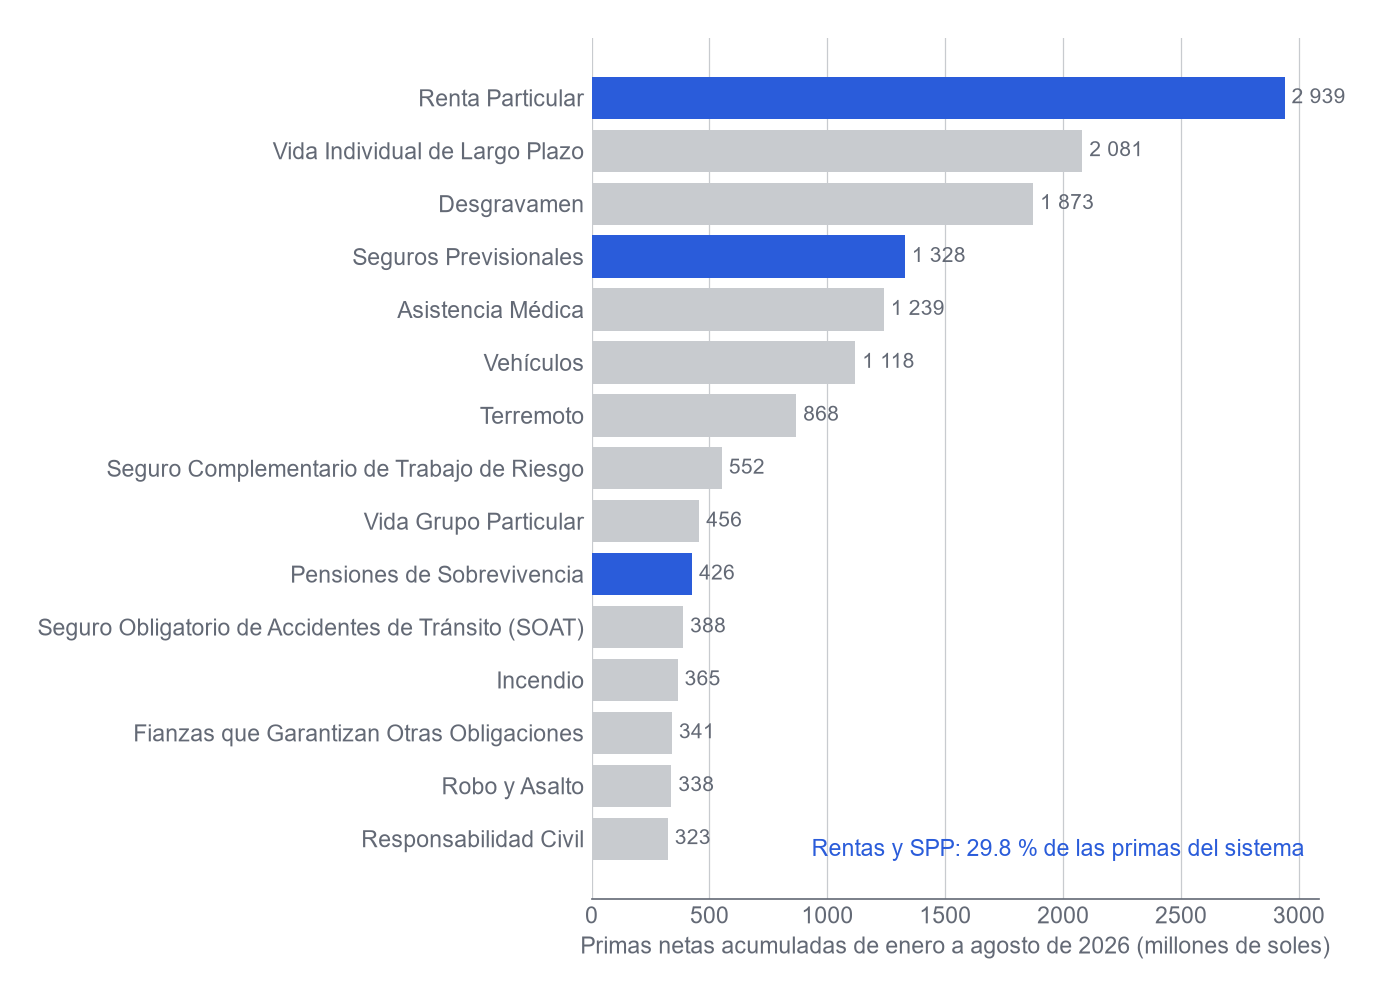

In [14]:
RIESGOS_RENTAS_SPP = [
    "Renta Particular",
    "Renta de Jubilados",
    "Seguros Previsionales",
    "Pensiones de Invalidez",
    "Pensiones de Sobrevivencia",
]
es_rentas_spp = por_riesgo["riesgo"].isin(RIESGOS_RENTAS_SPP)
participacion_rentas_spp = por_riesgo.loc[es_rentas_spp, "ago_2026"].sum() / total_sistema

principales = por_riesgo.head(15).iloc[::-1]
colores = [
    COLOR_HALLAZGO if riesgo in RIESGOS_RENTAS_SPP else COLOR_CONTEXTO
    for riesgo in principales["riesgo"]
]
figura, eje = plt.subplots(figsize=(9, 6.5))
barras = eje.barh(principales["riesgo"], principales["ago_2026"] / 1_000, color=colores)
for barra, valor in zip(barras, principales["ago_2026"], strict=True):
    eje.text(
        barra.get_width() + 30,
        barra.get_y() + barra.get_height() / 2,
        numero(valor / 1_000),
        va="center",
        fontsize=10,
        color=COLOR_TEXTO,
    )
eje.set_xlabel("Primas netas acumuladas de enero a agosto de 2026 (millones de soles)")
eje.grid(axis="y", visible=False)
eje.grid(axis="x", visible=True)
eje.text(
    0.98,
    0.05,
    f"Rentas y SPP: {porcentaje(participacion_rentas_spp)} de las primas del sistema",
    transform=eje.transAxes,
    ha="right",
    color=COLOR_HALLAZGO,
    fontsize=11,
)
figura.tight_layout()
plt.show()

*Nota.* Elaboración propia con datos de SBS (s. f.-b). En azul, los riesgos de rentas y del Sistema Privado de Pensiones; en gris, los demás.

La figura 2 compara las dos medidas de crecimiento de O2 en los riesgos sobre el umbral. Se destacan los riesgos en que la variación interanual y la TCAC tienen signo opuesto: su cuadrante depende de la medida que elija el paquete 3.2.

**Figura 2**

*Variación interanual frente a TCAC 2019-2025 de las primas netas, riesgos con al menos S/ 5 000 miles en agosto de 2026*

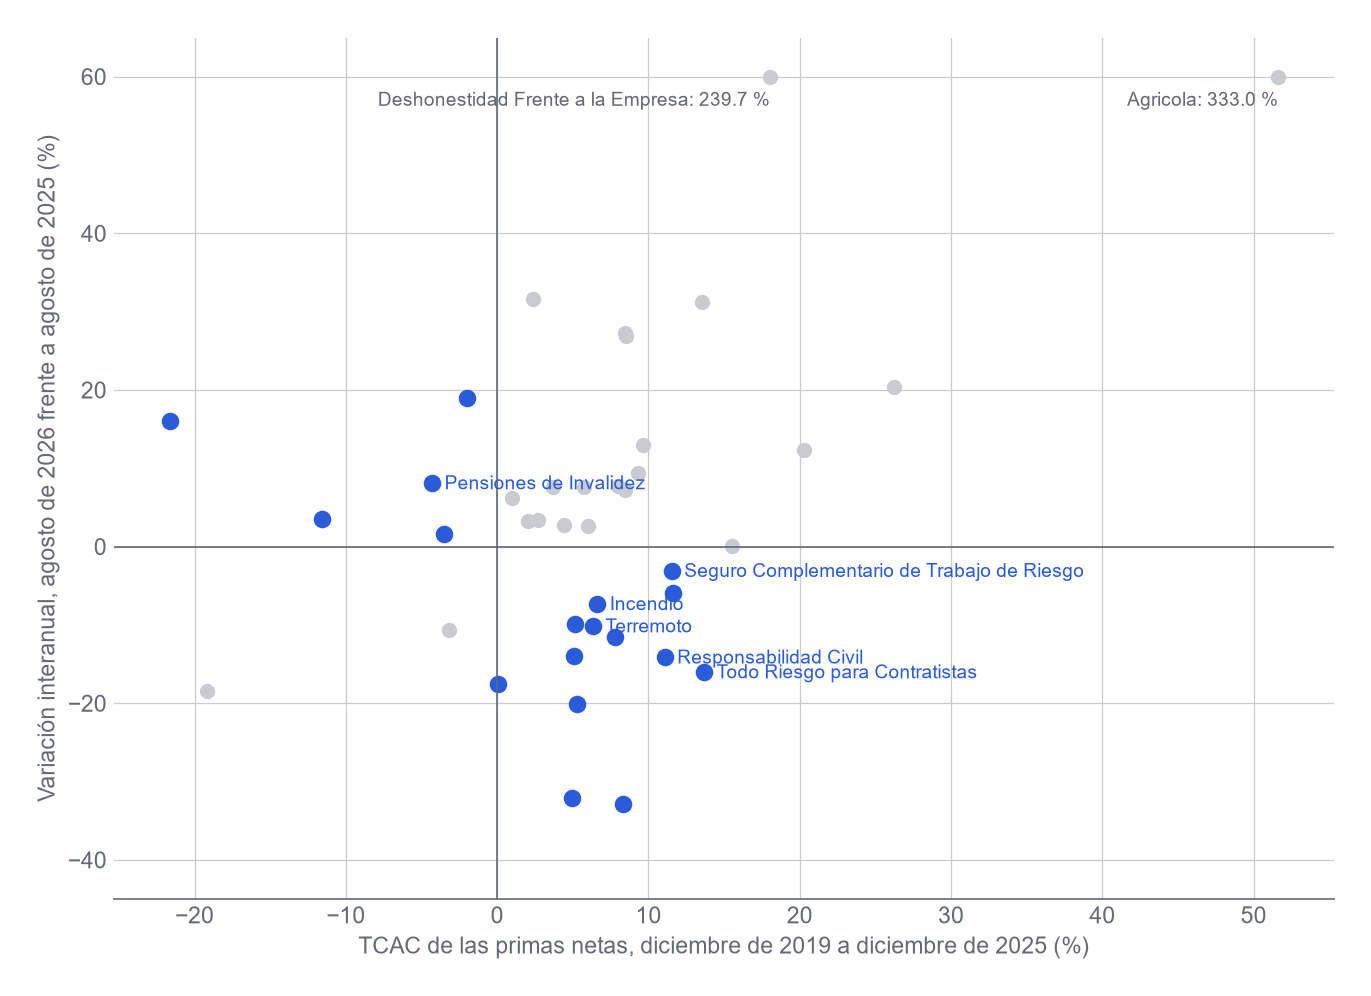

Riesgos sobre el umbral con ambas medidas: 40 | con signo opuesto: 18 | variación negativa y TCAC positiva: 13


In [15]:
crecimiento = sobre_umbral.dropna(subset=["variacion", "tcac"]).copy()
crecimiento["signo_opuesto"] = np.sign(crecimiento["variacion"]) != np.sign(crecimiento["tcac"])
opuestos = crecimiento[crecimiento["signo_opuesto"]]
opuestos_grandes = opuestos[opuestos["participacion"] >= 0.01]
LIMITE_Y = 60  # el eje vertical se corta en 60 %; los riesgos que lo superan van al borde

figura, eje = plt.subplots(figsize=(9, 6.5))
for subconjunto, color, tamano in [
    (crecimiento[~crecimiento["signo_opuesto"]], COLOR_CONTEXTO, 40),
    (opuestos, COLOR_HALLAZGO, 55),
]:
    eje.scatter(
        100 * subconjunto["tcac"],
        (100 * subconjunto["variacion"]).clip(upper=LIMITE_Y),
        s=tamano,
        color=color,
    )
eje.axhline(0, color=COLOR_TEXTO, linewidth=0.8)
eje.axvline(0, color=COLOR_TEXTO, linewidth=0.8)
for fila in opuestos_grandes.itertuples():
    eje.annotate(
        fila.riesgo,
        (100 * fila.tcac, 100 * fila.variacion),
        xytext=(6, -3),
        textcoords="offset points",
        fontsize=9,
        color=COLOR_HALLAZGO,
    )
for fila in crecimiento[100 * crecimiento["variacion"] > LIMITE_Y].itertuples():
    eje.annotate(
        f"{fila.riesgo}: {porcentaje(fila.variacion)}",
        (100 * fila.tcac, LIMITE_Y),
        xytext=(0, -14),
        textcoords="offset points",
        ha="right",
        fontsize=9,
        color=COLOR_TEXTO,
    )
eje.set_ylim(-45, LIMITE_Y + 5)
eje.set_xlabel("TCAC de las primas netas, diciembre de 2019 a diciembre de 2025 (%)")
eje.set_ylabel("Variación interanual, agosto de 2026 frente a agosto de 2025 (%)")
eje.grid(axis="x", visible=True)
figura.tight_layout()
plt.show()
print(
    "Riesgos sobre el umbral con ambas medidas:",
    len(crecimiento),
    "| con signo opuesto:",
    len(opuestos),
    "| variación negativa y TCAC positiva:",
    int(((crecimiento["variacion"] < 0) & (crecimiento["tcac"] > 0)).sum()),
)

*Nota.* Elaboración propia con datos de SBS (s. f.-b). En azul, los riesgos en que las dos medidas tienen signo opuesto; se rotulan los que tienen al menos 1 % de las primas del sistema. El eje vertical se corta en 60 %: los riesgos que lo superan se dibujan en el borde con su cifra. Se omite Fianzas que Garantizan Otras Obligaciones, sin TCAC porque no se publica en 2019.

## 3. Siniestralidad

Los índices de siniestralidad directa (P015) y retenida (P016) se leen tal como los publica la SBS en la columna Total, sin sumarlos. La tabla 6 resume su distribución por riesgo en agosto de 2026, para todos los riesgos y para los que superan el umbral de O2.

In [16]:
indices = consultar(
    """
    select s.riesgo_id,
           s.riesgo,
           s.siniestros_netos,
           s.siniestros_retenidos,
           s.indice_siniestralidad_directa,
           s.indice_siniestralidad_retenida
    from vw_siniestralidad_riesgo s
    where s.fecha_corte = :fecha_corte
      and s.tipo_riesgo = :tipo_riesgo
      and s.tipo_columna = :tipo_total
    """,
    fecha_corte=AGO_2026.date(),
    tipo_riesgo="riesgo",
    tipo_total="total_simple",
).set_index("riesgo_id")
indices = indices.join(por_riesgo[["ago_2026", "sobre_umbral"]])


def distribucion(serie: pd.Series) -> dict[str, str]:
    """Resumen de la distribución de un índice publicado, en porcentaje."""
    return {
        "Riesgos": numero(serie.count()),
        "Mínimo": numero(serie.min(), 1),
        "Percentil 25": numero(serie.quantile(0.25), 1),
        "Mediana": numero(serie.median(), 1),
        "Percentil 75": numero(serie.quantile(0.75), 1),
        "Máximo": numero(serie.max(), 1),
        "Igual a 0": numero((serie == 0).sum()),
        "Negativos": numero((serie < 0).sum()),
        "Mayores que 100 %": numero((serie > 100).sum()),
    }


tabla_6 = (
    pd.DataFrame(
        {
            "Directa, todos": distribucion(indices["indice_siniestralidad_directa"]),
            "Retenida, todos": distribucion(indices["indice_siniestralidad_retenida"]),
            "Directa, ≥ umbral": distribucion(
                indices.loc[indices["sobre_umbral"], "indice_siniestralidad_directa"]
            ),
            "Retenida, ≥ umbral": distribucion(
                indices.loc[indices["sobre_umbral"], "indice_siniestralidad_retenida"]
            ),
        }
    )
    .rename_axis("Estadístico")
    .reset_index()
)

**Tabla 6**

*Distribución de los índices de siniestralidad directa y retenida publicados por riesgo, agosto de 2026, en porcentaje*

In [17]:
mostrar(tabla_6)

Estadístico,"Directa, todos","Retenida, todos","Directa, ≥ umbral","Retenida, ≥ umbral"
Riesgos,50,50,41,41
Mínimo,-78.5,-22.3,7.9,2.0
Percentil 25,13.0,11.4,22.3,14.4
Mediana,31.5,28.8,33.5,32.5
Percentil 75,60.3,55.4,60.8,55.4
Máximo,1 853.2,24 627.2,1 853.2,1 853.2
Igual a 0,5,4,0,0
Negativos,1,3,0,0
Mayores que 100 %,2,3,2,1


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Índices de la columna Total de P015 y P016 para los 50 riesgos de tipo `riesgo`. «≥ umbral»: riesgos con primas netas de al menos S/ 5 000 miles en agosto de 2026.

**Figura 3**

*Índices de siniestralidad directa y retenida publicados por riesgo, riesgos con al menos S/ 5 000 miles en agosto de 2026*

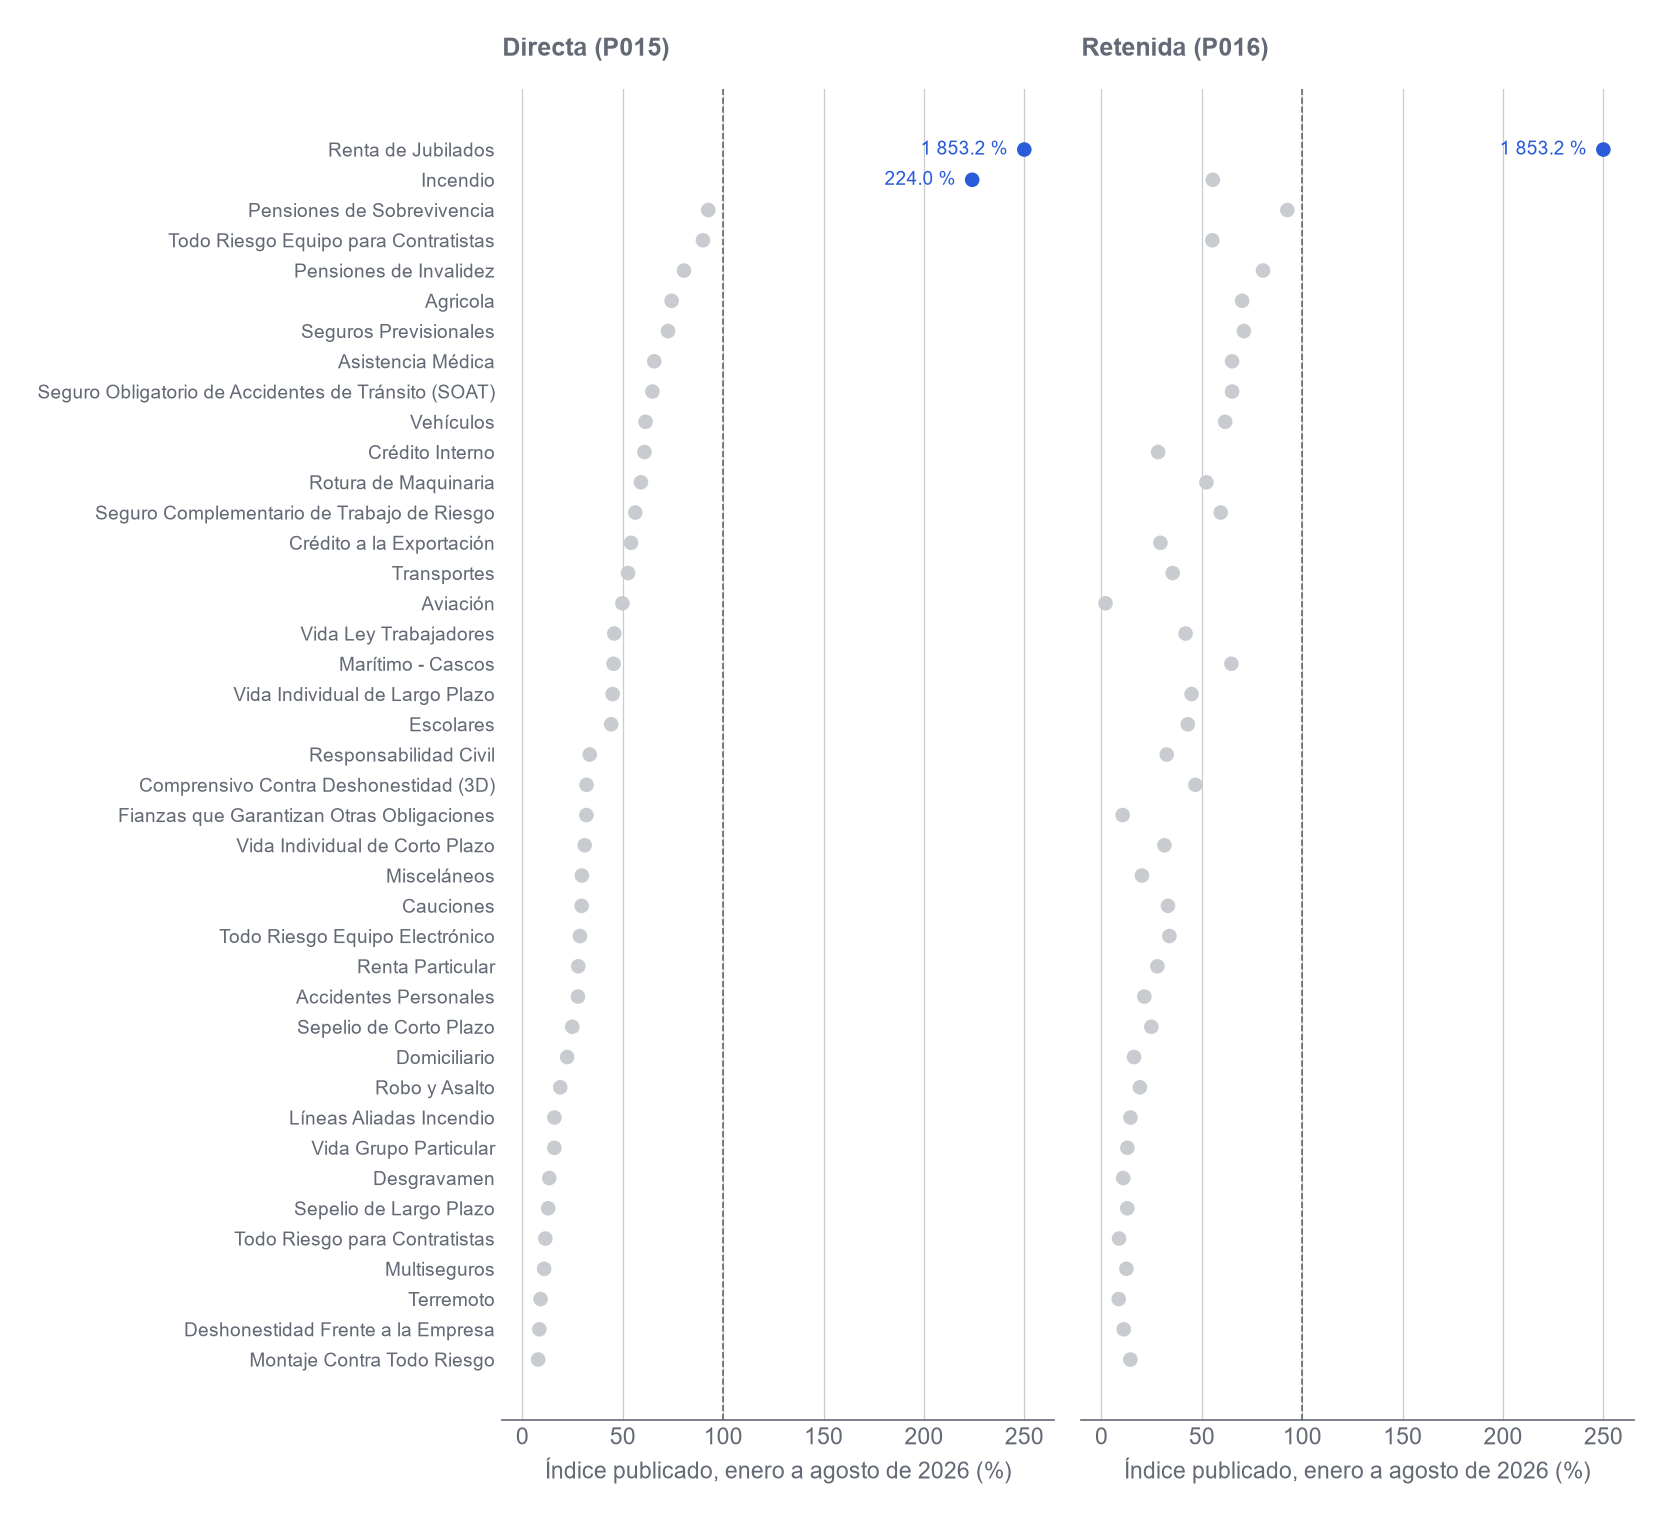

In [18]:
umbral_indices = indices[indices["sobre_umbral"]].sort_values("indice_siniestralidad_directa")
LIMITE_EJE = 250  # el eje se corta en 250 %; los índices que lo superan van al borde
posiciones = np.arange(len(umbral_indices))
figura, ejes = plt.subplots(1, 2, figsize=(11, 10), sharey=True)
for eje, columna, titulo in [
    (ejes[0], "indice_siniestralidad_directa", "Directa (P015)"),
    (ejes[1], "indice_siniestralidad_retenida", "Retenida (P016)"),
]:
    valores = umbral_indices[columna]
    colores = [COLOR_HALLAZGO if valor > 100 else COLOR_CONTEXTO for valor in valores]
    eje.scatter(valores.clip(upper=LIMITE_EJE), posiciones, s=36, color=colores, zorder=3)
    eje.axvline(100, color=COLOR_TEXTO, linewidth=0.8, linestyle="--")
    eje.set_xlim(-10, LIMITE_EJE + 15)
    for posicion, valor in zip(posiciones, valores, strict=True):
        if valor > 100:
            eje.annotate(
                f"{numero(valor, 1)} %",
                (min(valor, LIMITE_EJE), posicion),
                xytext=(-8, 0),
                textcoords="offset points",
                ha="right",
                va="center",
                fontsize=9,
                color=COLOR_HALLAZGO,
            )
    eje.set_title(titulo, fontsize=12, fontweight="bold", color=COLOR_TEXTO)
    eje.set_xlabel("Índice publicado, enero a agosto de 2026 (%)")
    eje.grid(axis="y", visible=False)
    eje.grid(axis="x", visible=True)
ejes[0].set_yticks(posiciones, umbral_indices["riesgo"], fontsize=9)
figura.tight_layout()
plt.show()

*Nota.* Elaboración propia con datos de SBS (s. f.-b). Riesgos ordenados por el índice directo. En azul, los índices mayores que 100 %, con su cifra. La línea discontinua marca 100 %. El eje se corta en 250 %: Renta de Jubilados se dibuja en el borde.

Incendio es el único riesgo de los ramos generales sobre el umbral con un índice directo mayor que 100 % en agosto de 2026. La apertura por empresa muestra si el resultado es general o se concentra en pocas compañías.

In [19]:
incendio = consultar(
    """
    select s.entidad,
           p.primas_netas,
           s.siniestros_netos,
           s.indice_siniestralidad_directa
    from vw_siniestralidad_riesgo s
    join vw_produccion_riesgo p
      on p.fecha_corte = s.fecha_corte
     and p.columna_id = s.columna_id
     and p.riesgo_id = s.riesgo_id
    where s.fecha_corte = :fecha_corte
      and s.riesgo = :riesgo
      and s.tipo_columna = :tipo_empresa
      and p.primas_netas >= :umbral
    order by p.primas_netas desc
    """,
    fecha_corte=AGO_2026.date(),
    riesgo="Incendio",
    tipo_empresa="empresa",
    umbral=UMBRAL_O2,
)
incendio_altos = incendio[incendio["indice_siniestralidad_directa"] > 100]
fila_incendio = indices[indices["riesgo"] == "Incendio"].iloc[0]
primas_incendio = fila_incendio["ago_2026"]
print(
    "Incendio, total del sistema: índice directo",
    f"{numero(fila_incendio['indice_siniestralidad_directa'], 1)} %, índice retenido",
    f"{numero(fila_incendio['indice_siniestralidad_retenida'], 1)} %",
)
print(
    "Incendio, ago. 2026: empresas con primas ≥ S/ 5 000 miles:",
    len(incendio),
    "| con índice directo > 100 %:",
    len(incendio_altos),
    "| primas de esas empresas:",
    numero(incendio_altos["primas_netas"].sum()),
    "de",
    numero(primas_incendio),
    "miles del riesgo",
)
for fila in incendio.itertuples():
    indice = numero(fila.indice_siniestralidad_directa, 1)
    print(
        f"  {fila.entidad}: primas {numero(fila.primas_netas)} miles, siniestros "
        f"{numero(fila.siniestros_netos)} miles, índice {indice} %"
    )

Incendio, total del sistema: índice directo 224.0 %, índice retenido 55.4 %
Incendio, ago. 2026: empresas con primas ≥ S/ 5 000 miles: 5 | con índice directo > 100 %: 5 | primas de esas empresas: 364 534 de 364 552 miles del riesgo
  Mapfre Perú (antes Mapfre Perú Vida): primas 164 587 miles, siniestros 414 261 miles, índice 251.7 %
  Rímac: primas 142 296 miles, siniestros 287 216 miles, índice 201.8 %
  La Positiva: primas 27 866 miles, siniestros 28 378 miles, índice 101.8 %
  Pacífico Compañía de Seguros y Reaseguros: primas 21 837 miles, siniestros 74 282 miles, índice 340.2 %
  Chubb Seguros Perú: primas 7 948 miles, siniestros 8 379 miles, índice 105.4 %


O2 exige que la siniestralidad calculada como siniestros netos entre primas netas replique el índice total del sistema publicado en P015 con una diferencia no mayor de 0.1 puntos porcentuales. La tabla 7 lo prueba en los 9 cortes con la columna Total (fila TOTAL del catálogo) y también con la suma de los riesgos de las empresas vigentes.

In [20]:
# Fila TOTAL de las columnas Total publicadas. En diciembre de 2020 la SBS rotula el total
# ampliado de forma distinta según la hoja, así que se agrega por corte y tipo de columna.
primas_total = consultar(
    """
    select fecha_corte,
           tipo_columna,
           sum(primas_netas) as primas_netas,
           count(primas_netas) as n_primas_netas,
           sum(primas_retenidas) as primas_retenidas,
           count(primas_retenidas) as n_primas_retenidas
    from vw_produccion_riesgo
    where tipo_riesgo = :tipo_total
      and empresa_id is null
    group by fecha_corte, tipo_columna
    """,
    tipo_total="total",
)
siniestros_total = consultar(
    """
    select fecha_corte,
           tipo_columna,
           sum(siniestros_netos) as siniestros_netos,
           count(siniestros_netos) as n_siniestros_netos,
           sum(siniestros_retenidos) as siniestros_retenidos,
           count(siniestros_retenidos) as n_siniestros_retenidos,
           max(indice_siniestralidad_directa) as indice_siniestralidad_directa,
           max(indice_siniestralidad_retenida) as indice_siniestralidad_retenida
    from vw_siniestralidad_riesgo
    where tipo_riesgo = :tipo_total
      and empresa_id is null
    group by fecha_corte, tipo_columna
    """,
    tipo_total="total",
)
totales = primas_total.merge(siniestros_total, on=["fecha_corte", "tipo_columna"])
totales["fecha_corte"] = pd.to_datetime(totales["fecha_corte"])
totales = totales.sort_values(["fecha_corte", "tipo_columna"])
# Cada medida sale de una sola columna publicada por corte y tipo: la suma no duplica cifras.
assert (totales.filter(like="n_") <= 1).all().all()

siniestros_empresas = consultar(
    """
    select fecha_corte,
           sum(siniestros_netos) as siniestros_netos
    from vw_siniestralidad_riesgo
    where tipo_riesgo = :tipo_riesgo
      and tipo_columna = :tipo_empresa
      and estado = :estado
    group by fecha_corte
    """,
    tipo_riesgo="riesgo",
    tipo_empresa="empresa",
    estado="vigente",
)
siniestros_empresas["fecha_corte"] = pd.to_datetime(siniestros_empresas["fecha_corte"])
siniestros_empresas = siniestros_empresas.set_index("fecha_corte")["siniestros_netos"]

simple = totales[totales["tipo_columna"] == "total_simple"].set_index("fecha_corte")
ampliado = totales[totales["tipo_columna"] == "total_ampliado"].set_index("fecha_corte")
contraste = pd.DataFrame(index=simple.index)
contraste["publicado"] = simple["indice_siniestralidad_directa"]
contraste["calculado_total"] = 100 * simple["siniestros_netos"] / simple["primas_netas"]
contraste["calculado_empresas"] = 100 * siniestros_empresas / primas_calculadas.sum()
contraste["calculado_ampliado"] = 100 * ampliado["siniestros_netos"] / ampliado["primas_netas"]
contraste["diferencia"] = contraste["calculado_total"] - contraste["publicado"]
contraste["retenido_publicado"] = simple["indice_siniestralidad_retenida"]
contraste["retenido_calculado"] = 100 * simple["siniestros_retenidos"] / simple["primas_retenidas"]
contraste["diferencia_retenida"] = contraste["retenido_calculado"] - contraste["retenido_publicado"]
contraste["retenido_ampliado"] = (
    100 * ampliado["siniestros_retenidos"] / ampliado["primas_retenidas"]
)

tabla_7 = pd.DataFrame(
    {
        "Corte": contraste.index.map(corte_texto),
        "Directa publicada": contraste["publicado"].map(lambda v: numero(v, 4)),
        "Calculada con el Total": contraste["calculado_total"].map(lambda v: numero(v, 4)),
        "Calculada con las empresas": contraste["calculado_empresas"].map(lambda v: numero(v, 4)),
        "Calculada con el total ampliado": contraste["calculado_ampliado"].map(
            lambda v: numero(v, 4)
        ),
        "Diferencia (p. p.)": contraste["diferencia"].map(lambda v: numero(v, 4)),
        "Retenida publicada": contraste["retenido_publicado"].map(lambda v: numero(v, 4)),
        "Retenida calculada": contraste["retenido_calculado"].map(lambda v: numero(v, 4)),
        "Retenida con el total ampliado": contraste["retenido_ampliado"].map(
            lambda v: numero(v, 4)
        ),
        "Diferencia retenida (p. p.)": contraste["diferencia_retenida"].map(lambda v: numero(v, 4)),
        "Cumple 0.1 p. p.": (
            (contraste["diferencia"].abs() <= 0.1) & (contraste["diferencia_retenida"].abs() <= 0.1)
        ).map({True: "Sí", False: "No"}),
    }
)

**Tabla 7**

*Índice de siniestralidad del total del sistema: publicado en P015 y P016 frente al calculado, en porcentaje*

In [21]:
mostrar(tabla_7)

Corte,Directa publicada,Calculada con el Total,Calculada con las empresas,Calculada con el total ampliado,Diferencia (p. p.),Retenida publicada,Retenida calculada,Retenida con el total ampliado,Diferencia retenida (p. p.),Cumple 0.1 p. p.
dic. 2019,52.9937,52.9937,52.9937,s. d.,0.0000,45.9940,45.9940,s. d.,0.0000,Sí
dic. 2020,51.6962,51.6962,51.6962,51.6961,0.0000,51.8606,51.8606,51.8621,0.0000,Sí
dic. 2021,59.3104,59.3104,59.3104,s. d.,0.0000,52.8718,52.8718,s. d.,0.0000,Sí
dic. 2022,53.9549,52.1325,52.1325,53.9549,-1.8223,44.7619,44.6362,44.7619,-0.1258,No
dic. 2023,47.7583,47.7583,47.7583,s. d.,0.0000,45.8840,45.8840,s. d.,0.0000,Sí
dic. 2024,43.0752,43.0752,43.0752,s. d.,0.0000,42.1865,42.1865,s. d.,0.0000,Sí
ago. 2025,41.3714,41.3714,41.3714,s. d.,0.0000,40.2534,40.2534,s. d.,0.0000,Sí
dic. 2025,39.4169,39.4169,39.4169,s. d.,0.0000,39.2973,39.2973,s. d.,0.0000,Sí
ago. 2026,48.9141,48.9141,48.9141,s. d.,0.0000,45.7487,45.7487,s. d.,0.0000,Sí


*Nota.* Elaboración propia con datos de SBS (s. f.-b). Calculada = 100 × siniestros / primas del mismo corte: con la columna Total (total simple), con la suma de los riesgos de las empresas vigentes o con el total ampliado («Total + …», solo en diciembre de 2020 y de 2022; «s. d.» en los demás cortes). Diferencia = calculada con el Total − publicada.

**Figura 4**

*Diferencia entre la siniestralidad directa calculada con la columna Total y el índice publicado del total del sistema, por corte, en puntos porcentuales*

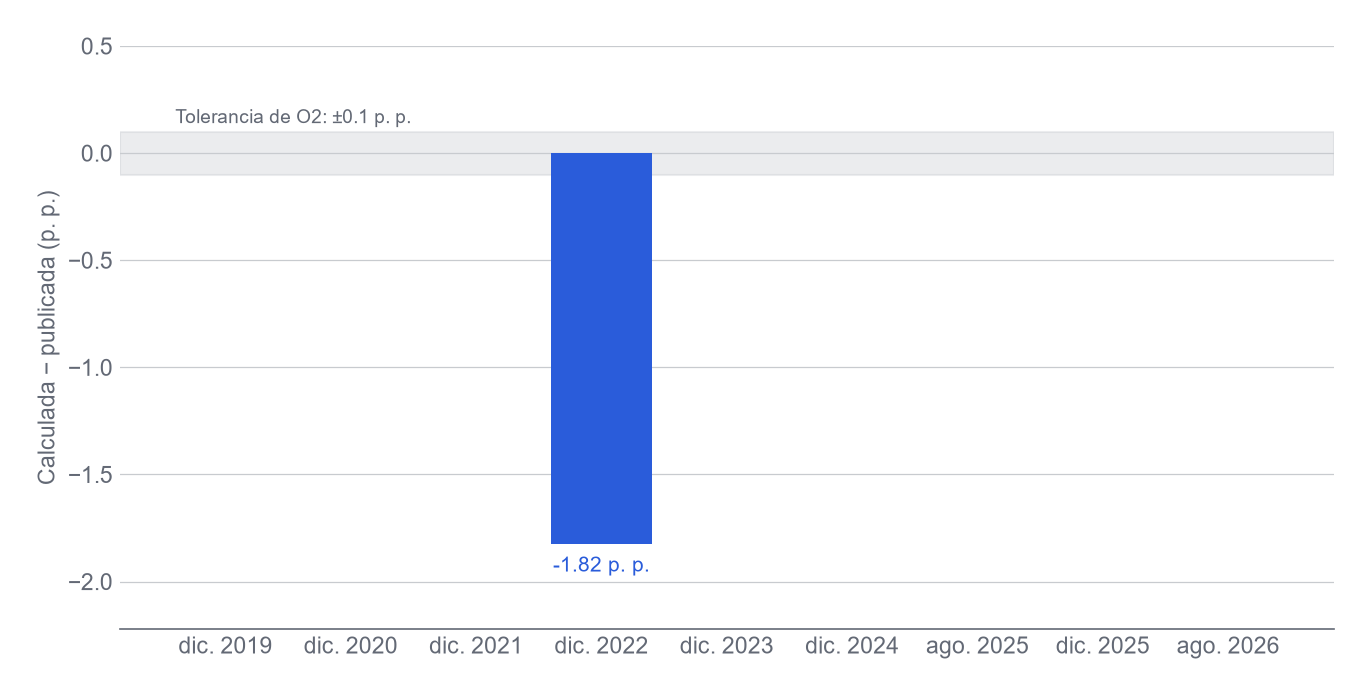

In [22]:
figura, eje = plt.subplots(figsize=(9, 4.5))
etiquetas = contraste.index.map(corte_texto)
diferencias = contraste["diferencia"]
colores = [COLOR_HALLAZGO if abs(v) > 0.1 else COLOR_CONTEXTO for v in diferencias]
barras = eje.bar(etiquetas, diferencias, color=colores)
eje.axhspan(-0.1, 0.1, color=COLOR_CONTEXTO, alpha=0.35, zorder=0)
for barra, valor in zip(barras, diferencias, strict=True):
    if abs(valor) > 0.1:
        eje.text(
            barra.get_x() + barra.get_width() / 2,
            valor - 0.06 if valor < 0 else valor + 0.06,
            f"{numero(valor, 2)} p. p.",
            ha="center",
            va="top" if valor < 0 else "bottom",
            fontsize=10,
            color=COLOR_HALLAZGO,
        )
eje.text(-0.4, 0.14, "Tolerancia de O2: ±0.1 p. p.", fontsize=9, color=COLOR_TEXTO)
eje.set_ylabel("Calculada − publicada (p. p.)")
eje.set_ylim(min(diferencias.min() - 0.4, -0.5), 0.5)
figura.tight_layout()
plt.show()

*Nota.* Elaboración propia con datos de SBS (s. f.-b). En azul, los cortes fuera de la tolerancia de 0.1 p. p.; la franja gris marca la tolerancia de O2. En los demás cortes la diferencia redondea a 0.0000 p. p. (tabla 7).

## 4. Casos atípicos

Cada caso se cuenta en las celdas empresa × riesgo de tipo `riesgo` (columnas de empresa), salvo que se indique otra cosa, y se evalúa si afecta a O2: la matriz usa los riesgos con primas netas de al menos S/ 5 000 miles en agosto de 2026, su crecimiento (agosto de 2026 frente a agosto de 2025 y TCAC 2019-2025) y el índice total del sistema de agosto de 2026.

In [23]:
celdas = consultar(
    """
    select s.fecha_corte,
           s.empresa_id,
           s.entidad,
           s.estado,
           s.riesgo_id,
           s.riesgo,
           s.siniestros_netos,
           s.indice_siniestralidad_directa,
           s.indice_siniestralidad_retenida,
           p.primas_netas
    from vw_siniestralidad_riesgo s
    join vw_produccion_riesgo p
      on p.fecha_corte = s.fecha_corte
     and p.columna_id = s.columna_id
     and p.riesgo_id = s.riesgo_id
    where s.tipo_riesgo = :tipo_riesgo
      and s.tipo_columna = :tipo_empresa
    """,
    tipo_riesgo="riesgo",
    tipo_empresa="empresa",
)
celdas["fecha_corte"] = pd.to_datetime(celdas["fecha_corte"])
celdas["directa"] = celdas["indice_siniestralidad_directa"]


def ejemplos(
    filas: pd.DataFrame, columna: str, cuantos: int = 3, decimales: int = 0, sufijo: str = " miles"
) -> str:
    """Texto con los primeros ejemplos: corte, empresa, riesgo y cifra."""
    textos = [
        f"{corte_texto(fila.fecha_corte)}, {fila.entidad}, {fila.riesgo}: "
        f"{numero(getattr(fila, columna), decimales)}{sufijo}"
        for fila in filas.head(cuantos).itertuples()
    ]
    return "; ".join(textos)


atipicos: list[dict[str, str]] = []

### 4.1 Primas o siniestros negativos

In [24]:
primas_negativas = celdas[celdas["primas_netas"] < 0].sort_values("primas_netas")
siniestros_negativos = celdas[celdas["siniestros_netos"] < 0].sort_values("siniestros_netos")
negativos_umbral = primas_negativas[primas_negativas["primas_netas"] <= -UMBRAL_O2]
riesgos_negativos_sistema = por_riesgo[por_riesgo["ago_2026"] < 0]["riesgo"].tolist()

# Seguro de Bancos (BBB) en agosto de 2026: el total del sistema con y sin la celda negativa.
bancos_2026 = de_empresas[
    (de_empresas["riesgo"] == "Seguro de Bancos (BBB)") & (de_empresas["fecha_corte"] == AGO_2026)
]
bancos_total = bancos_2026["primas_netas"].sum()
bancos_sin_negativas = bancos_2026.loc[bancos_2026["primas_netas"] > 0, "primas_netas"].sum()
atipicos.append(
    {
        "Tipo": "Primas netas negativas",
        "Cantidad": f"{len(primas_negativas)} celdas en "
        f"{primas_negativas['fecha_corte'].nunique()} cortes ({len(negativos_umbral)} de "
        "−S/ 5 000 miles o menos)",
        "Ejemplos": ejemplos(primas_negativas, "primas_netas", decimales=2),
        "¿Afecta a O2?": "Sí: la celda negativa de ago. 2026 deja Seguro de Bancos (BBB) en "
        f"{numero(bancos_total)} miles, bajo el umbral (sin ella sumaría "
        f"{numero(bancos_sin_negativas)}); en el total del sistema solo "
        f"{', '.join(riesgos_negativos_sistema)} es negativo, también bajo el umbral",
    }
)
atipicos.append(
    {
        "Tipo": "Siniestros netos negativos",
        "Cantidad": f"{len(siniestros_negativos)} celdas",
        "Ejemplos": ejemplos(siniestros_negativos, "siniestros_netos", decimales=2),
        "¿Afecta a O2?": "Sí en las celdas empresa × riesgo: "
        f"{int((siniestros_negativos['primas_netas'] >= UMBRAL_O2).sum())} superan el umbral y "
        "su índice sale negativo; no en el total del sistema de ago. 2026, donde ningún riesgo "
        "sobre el umbral tiene siniestros netos negativos",
    }
)
print("Primas negativas:", len(primas_negativas), "| ≤ −S/ 5 000 miles:", len(negativos_umbral))
print("Siniestros negativos:", len(siniestros_negativos))
print(
    "Riesgos sobre el umbral con siniestros netos negativos en el total, ago. 2026:",
    int((indices.loc[indices["sobre_umbral"], "siniestros_netos"] < 0).sum()),
)

Primas negativas: 49 | ≤ −S/ 5 000 miles: 2
Siniestros negativos: 290
Riesgos sobre el umbral con siniestros netos negativos en el total, ago. 2026: 0


### 4.2 Índices nulos, negativos o mayores que 100 %

In [25]:
indices_nulos = celdas[celdas["directa"].isna()]
indices_negativos = celdas[celdas["directa"] < 0].sort_values("directa")
indices_altos = celdas[celdas["directa"] > 100].sort_values("directa", ascending=False)
columnas_nulas = sorted(set(indices_nulos["entidad"] + " (" + indices_nulos["estado"] + ")"))

fuera_de_rango = celdas[(celdas["directa"] < 0) | (celdas["directa"] > 100)]
fuera_sobre_umbral = fuera_de_rango[fuera_de_rango["primas_netas"] >= UMBRAL_O2]
con_indice = celdas[celdas["directa"].notna()]
celdas_sobre_umbral = con_indice[con_indice["primas_netas"] >= UMBRAL_O2]
celdas_bajo_umbral = con_indice[con_indice["primas_netas"] < UMBRAL_O2]
tasa_fuera_sobre = len(fuera_sobre_umbral) / len(celdas_sobre_umbral)
tasa_fuera_bajo = (len(fuera_de_rango) - len(fuera_sobre_umbral)) / len(celdas_bajo_umbral)
fuera_rentas_spp = fuera_sobre_umbral["riesgo"].isin(RIESGOS_RENTAS_SPP).sum()
negativos_sobre = int((fuera_sobre_umbral["directa"] < 0).sum())
altos_sobre = int((fuera_sobre_umbral["directa"] > 100).sum())
riesgos_altos_umbral = indices[
    indices["sobre_umbral"] & (indices["indice_siniestralidad_directa"] > 100)
]["riesgo"].tolist()

atipicos.append(
    {
        "Tipo": "Índices nulos",
        "Cantidad": f"{len(indices_nulos)} celdas",
        "Ejemplos": "Columnas sin índice publicado: " + "; ".join(columnas_nulas),
        "¿Afecta a O2?": "No: son los flujos de empresas liquidadas o absorbidas en dic. 2020 y "
        "dic. 2022, que P015 y P016 no publican",
    }
)
atipicos.append(
    {
        "Tipo": "Índices directos negativos",
        "Cantidad": f"{len(indices_negativos)} celdas",
        "Ejemplos": ejemplos(indices_negativos, "directa", decimales=1, sufijo=" %"),
        "¿Afecta a O2?": "No en el índice total del sistema; sí en las celdas empresa × riesgo: "
        f"{negativos_sobre} superan el umbral",
    }
)
atipicos.append(
    {
        "Tipo": "Índices directos mayores que 100 %",
        "Cantidad": f"{len(indices_altos)} celdas",
        "Ejemplos": ejemplos(indices_altos, "directa", decimales=1, sufijo=" %"),
        "¿Afecta a O2?": "Sí: en ago. 2026 superan 100 % en el total del sistema "
        + " y ".join(riesgos_altos_umbral)
        + f", ambos sobre el umbral; en las celdas empresa × riesgo, {altos_sobre} superan el "
        "umbral",
    }
)
print(
    "Índices nulos:",
    len(indices_nulos),
    "| negativos:",
    len(indices_negativos),
    "| mayores que 100 %:",
    len(indices_altos),
    "| celdas:",
    celdas["directa"].notna().sum(),
)
print(
    "Celdas fuera de 0-100 % con primas ≥ S/ 5 000 miles:",
    len(fuera_sobre_umbral),
    "de",
    len(celdas_sobre_umbral),
    f"({porcentaje(tasa_fuera_sobre)})",
    "| bajo el umbral:",
    len(fuera_de_rango) - len(fuera_sobre_umbral),
    "de",
    len(celdas_bajo_umbral),
    f"({porcentaje(tasa_fuera_bajo)})",
)
print(
    "De las celdas fuera de 0-100 % sobre el umbral, en rentas y SPP:",
    fuera_rentas_spp,
    f"({porcentaje(fuera_rentas_spp / len(fuera_sobre_umbral))})",
)
print(
    "Celdas con primas netas iguales a 0 e índice publicado 0:",
    int(((celdas["primas_netas"] == 0) & (celdas["directa"] == 0)).sum()),
)

Índices nulos: 144 | negativos: 260 | mayores que 100 %: 325 | celdas: 7804
Celdas fuera de 0-100 % con primas ≥ S/ 5 000 miles: 264 de 1652 (16.0 %) | bajo el umbral: 321 de 6152 (5.2 %)
De las celdas fuera de 0-100 % sobre el umbral, en rentas y SPP: 87 (33.0 %)
Celdas con primas netas iguales a 0 e índice publicado 0: 5303


La figura 5 relaciona el índice directo de cada celda empresa × riesgo con sus primas. Los índices fuera del rango de 0 a 100 % aparecen a ambos lados del umbral de O2, y son más frecuentes sobre él: el umbral no los filtra.

**Figura 5**

*Índice de siniestralidad directa publicado frente a las primas netas, celdas empresa × riesgo de los 9 cortes*

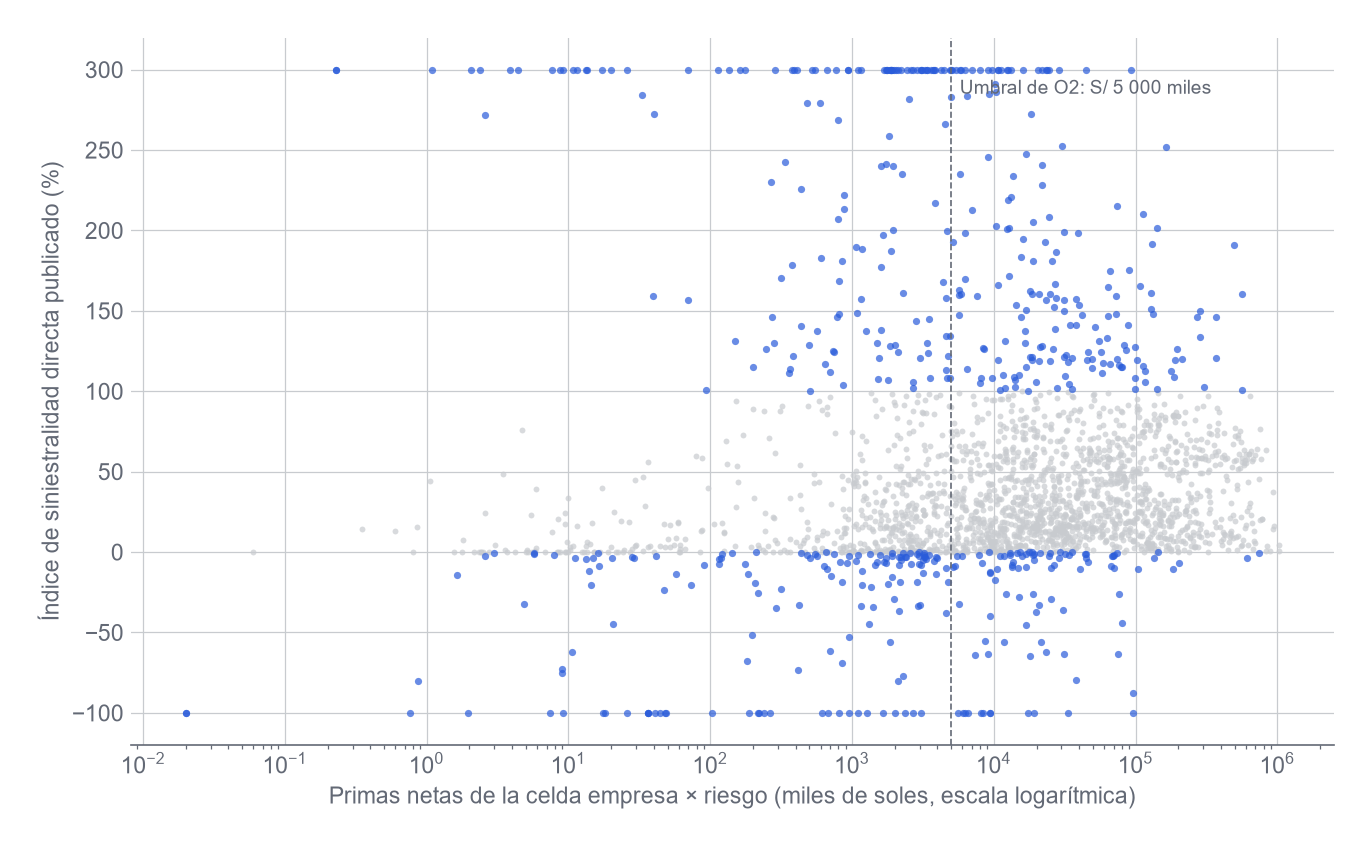

Celdas dibujadas: 2455 | fuera de 0-100 %: 562


In [26]:
dispersion = celdas[(celdas["primas_netas"] > 0) & celdas["directa"].notna()].copy()
dispersion["fuera"] = (dispersion["directa"] < 0) | (dispersion["directa"] > 100)
LIMITE_INFERIOR, LIMITE_SUPERIOR = -100, 300
figura, eje = plt.subplots(figsize=(9, 5.5))
for subconjunto, color, tamano in [
    (dispersion[~dispersion["fuera"]], COLOR_CONTEXTO, 8),
    (dispersion[dispersion["fuera"]], COLOR_HALLAZGO, 12),
]:
    eje.scatter(
        subconjunto["primas_netas"],
        subconjunto["directa"].clip(LIMITE_INFERIOR, LIMITE_SUPERIOR),
        s=tamano,
        color=color,
        alpha=0.7,
        linewidths=0,
    )
eje.set_xscale("log")
eje.axvline(UMBRAL_O2, color=COLOR_TEXTO, linewidth=0.8, linestyle="--")
eje.text(
    UMBRAL_O2 * 1.15,
    LIMITE_SUPERIOR - 15,
    "Umbral de O2: S/ 5 000 miles",
    fontsize=9,
    color=COLOR_TEXTO,
)
eje.set_xlabel("Primas netas de la celda empresa × riesgo (miles de soles, escala logarítmica)")
eje.set_ylabel("Índice de siniestralidad directa publicado (%)")
eje.grid(axis="x", visible=True)
figura.tight_layout()
plt.show()
print("Celdas dibujadas:", len(dispersion), "| fuera de 0-100 %:", int(dispersion["fuera"].sum()))

*Nota.* Elaboración propia con datos de SBS (s. f.-b). En azul, los índices negativos o mayores que 100 %; la línea discontinua marca el umbral de O2. Se omiten las celdas con primas nulas o negativas, que no se pueden dibujar en escala logarítmica, y las que no tienen índice. El eje vertical se corta en −100 % y 300 %: los índices fuera de ese rango se dibujan en el borde.

### 4.3 Riesgos con primas casi nulas o que no se publican en todos los cortes

In [27]:
CASI_NULAS = 1_000  # menos de S/ 1 millón en el total del sistema
casi_nulas = por_riesgo[por_riesgo["ago_2026"].abs() < CASI_NULAS]
no_todos = catalogo_riesgos[pd.to_datetime(catalogo_riesgos["corte_desde"]) > DIC_2019]
atipicos.append(
    {
        "Tipo": "Riesgos con primas casi nulas (< S/ 1 000 miles en ago. 2026)",
        "Cantidad": f"{len(casi_nulas)} riesgos",
        "Ejemplos": "; ".join(
            f"{fila.riesgo}: {numero(fila.ago_2026, 2)} miles" for fila in casi_nulas.itertuples()
        ),
        "¿Afecta a O2?": "No: quedan fuera por el umbral; sus índices publicados son 0 cuando "
        "no hay primas",
    }
)
atipicos.append(
    {
        "Tipo": "Riesgos que no se publican en todos los cortes",
        "Cantidad": f"{len(no_todos)} riesgos",
        "Ejemplos": "; ".join(
            f"{fila.riesgo}: desde {corte_texto(pd.Timestamp(fila.corte_desde))}"
            for fila in no_todos.itertuples()
        ),
        "¿Afecta a O2?": "Sí: no tienen TCAC 2019-2025 propia; Fianzas que garantizan otras "
        "obligaciones supera el umbral y se compara junto con Cauciones (Cauciones y fianzas: "
        f"TCAC {porcentaje(tcac_cauciones)}, variación interanual "
        f"{porcentaje(variacion_cauciones)})",
    }
)

### 4.4 Variaciones interanuales extremas

In [28]:
VARIACION_EXTREMA = 0.5  # ±50 % frente a agosto de 2025
extremas = por_riesgo[por_riesgo["variacion"].abs() >= VARIACION_EXTREMA].copy()
extremas_umbral = extremas[extremas["sobre_umbral"]]
seguro_bancos = por_riesgo[por_riesgo["riesgo"] == "Seguro de Bancos (BBB)"].iloc[0]
atipicos.append(
    {
        "Tipo": "Variación interanual extrema (|variación| ≥ 50 %, total del sistema)",
        "Cantidad": f"{len(extremas)} riesgos ({len(extremas_umbral)} sobre el umbral)",
        "Ejemplos": "; ".join(
            f"{fila.riesgo}: {porcentaje(fila.variacion)} "
            f"({numero(fila.ago_2025)} a {numero(fila.ago_2026)} miles)"
            for fila in extremas.itertuples()
        ),
        "¿Afecta a O2?": "Sí: "
        + " y ".join(extremas_umbral["riesgo"])
        + " entran en la matriz con crecimientos atípicos; Seguro de Bancos (BBB) sale del "
        f"universo ({numero(seguro_bancos['ago_2025'])} a {numero(seguro_bancos['ago_2026'])} "
        "miles)",
    }
)

### 4.5 Empresas con primas en un riesgo en un solo corte

In [29]:
con_primas = celdas[celdas["primas_netas"] != 0]
presencia_celda = con_primas.groupby(["empresa_id", "riesgo_id"]).agg(
    cortes=("fecha_corte", "nunique"),
    fecha_corte=("fecha_corte", "max"),
    entidad=("entidad", "last"),
    riesgo=("riesgo", "first"),
    primas_netas=("primas_netas", "sum"),
)
un_solo_corte = presencia_celda[presencia_celda["cortes"] == 1].sort_values(
    "primas_netas", ascending=False
)
atipicos.append(
    {
        "Tipo": "Empresa con primas en un riesgo en un solo corte",
        "Cantidad": f"{len(un_solo_corte)} pares empresa × riesgo",
        "Ejemplos": ejemplos(un_solo_corte, "primas_netas", cuantos=4, decimales=2),
        "¿Afecta a O2?": "No: todas las celdas están bajo S/ 5 000 miles, el umbral de las "
        "celdas empresa × riesgo",
    }
)

### 4.6 Rentas y Sistema Privado de Pensiones

In [30]:
rentas_spp = indices[indices["riesgo"].isin(RIESGOS_RENTAS_SPP)].sort_values(
    "ago_2026", ascending=False
)
atipicos.append(
    {
        "Tipo": "Rentas y SPP (siniestralidad no comparable)",
        "Cantidad": f"{len(rentas_spp)} riesgos, {porcentaje(participacion_rentas_spp)} de las "
        "primas de ago. 2026",
        "Ejemplos": "; ".join(
            f"{fila.riesgo}: {numero(fila.indice_siniestralidad_directa, 1)} %"
            for fila in rentas_spp.itertuples()
        ),
        "¿Afecta a O2?": "Sí: los cinco superan el umbral; entran en la matriz con una nota "
        "(acta, sección 4), porque el pago de pensiones y rentas no es comparable con el "
        "siniestro de un ramo general",
    }
)

### 4.7 Fila espuria de `dim_cuenta` (issue #34)

In [31]:
espuria = consultar(
    """
    select cuenta_id, clave, hoja
    from dim_cuenta
    where clave like :patron
    """,
    patron="%ACTUALIZADO%",
)
atipicos.append(
    {
        "Tipo": "Fila espuria de dim_cuenta (issue #34)",
        "Cantidad": f"{len(espuria)} fila",
        "Ejemplos": "; ".join(
            f"cuenta_id {fila.cuenta_id}, {fila.hoja}: «{fila.clave}»"
            for fila in espuria.itertuples()
        ),
        "¿Afecta a O2?": "No: es una nota al pie de P001 de dic. 2021; no entra en las vistas "
        "de riesgo",
    }
)

### 4.8 Resumen

**Tabla 8**

*Casos atípicos de las vistas de producción y siniestralidad por riesgo y su efecto en O2*

In [32]:
tabla_8 = pd.DataFrame(atipicos)
mostrar(tabla_8)

Tipo,Cantidad,Ejemplos,¿Afecta a O2?
Primas netas negativas,49 celdas en 9 cortes (2 de −S/ 5 000 miles o menos),"dic. 2022, Mapfre Perú (ramos generales), Aviación: -9 307.03 miles; ago. 2026, Mapfre Perú (antes Mapfre Perú Vida), Seguro de Bancos (BBB): -6 944.35 miles; dic. 2025, Mapfre Perú (antes Mapfre Perú Vida), Lucro Cesante: -4 212.57 miles","Sí: la celda negativa de ago. 2026 deja Seguro de Bancos (BBB) en 4 809 miles, bajo el umbral (sin ella sumaría 11 754); en el total del sistema solo Lucro Cesante es negativo, también bajo el umbral"
Siniestros netos negativos,290 celdas,"dic. 2024, Rímac, Aviación: -130 060.13 miles; dic. 2024, Rímac, Seguros Previsionales: -126 375.05 miles; dic. 2023, Rímac, Aviación: -83 997.69 miles","Sí en las celdas empresa × riesgo: 95 superan el umbral y su índice sale negativo; no en el total del sistema de ago. 2026, donde ningún riesgo sobre el umbral tiene siniestros netos negativos"
Índices nulos,144 celdas,Columnas sin índice publicado: Coface Seguro de Crédito Perú (liquidada); Mapfre Perú (ramos generales) (absorbida); Rigel Perú Compañía de Seguros de Vida (liquidada),"No: son los flujos de empresas liquidadas o absorbidas en dic. 2020 y dic. 2022, que P015 y P016 no publican"
Índices directos negativos,260 celdas,"dic. 2019, Quálitas Compañía de Seguros, Transportes: -31 295.9 %; dic. 2023, Crecer Seguros, Sepelio de Corto Plazo: -26 049.6 %; dic. 2020, Avla Perú Compañía de Seguros, Todo Riesgo Equipo Electrónico: -18 689.5 %",No en el índice total del sistema; sí en las celdas empresa × riesgo: 92 superan el umbral
Índices directos mayores que 100 %,325 celdas,"dic. 2024, Crecer Seguros, Sepelio de Corto Plazo: 6 481 400.0 %; ago. 2025, Vivir Seguros Compañía de Seguros de Vida, Accidentes Personales: 38 700.0 %; dic. 2020, Interseguro Compañía de Seguros, Renta de Jubilados: 24 562.0 %","Sí: en ago. 2026 superan 100 % en el total del sistema Renta de Jubilados y Incendio, ambos sobre el umbral; en las celdas empresa × riesgo, 172 superan el umbral"
Riesgos con primas casi nulas (< S/ 1 000 miles en ago. 2026),6 riesgos,Animales: 691.95 miles; Lucro Cesante Rotura de Maquinaria: 33.58 miles; Cristales: 0.00 miles; Líneas Aliadas Vehículos: 0.00 miles; Calderas: 0.00 miles; Fianzas que Garantizan Obligaciones Crediticias: 0.00 miles,No: quedan fuera por el umbral; sus índices publicados son 0 cuando no hay primas
Riesgos que no se publican en todos los cortes,2 riesgos,Fianzas que Garantizan Obligaciones Crediticias: desde dic. 2023; Fianzas que Garantizan Otras Obligaciones: desde dic. 2023,"Sí: no tienen TCAC 2019-2025 propia; Fianzas que garantizan otras obligaciones supera el umbral y se compara junto con Cauciones (Cauciones y fianzas: TCAC 11.0 %, variación interanual -1.2 %)"
"Variación interanual extrema (|variación| ≥ 50 %, total del sistema)",4 riesgos (2 sobre el umbral),Agricola: 333.0 % (17 243 a 74 666 miles); Deshonestidad Frente a la Empresa: 239.7 % (4 923 a 16 723 miles); Seguro de Bancos (BBB): -57.3 % (11 273 a 4 809 miles); Lucro Cesante Rotura de Maquinaria: 125.2 % (15 a 34 miles),Sí: Agricola y Deshonestidad Frente a la Empresa entran en la matriz con crecimientos atípicos; Seguro de Bancos (BBB) sale del universo (11 273 a 4 809 miles)
Empresa con primas en un riesgo en un solo corte,6 pares empresa × riesgo,"ago. 2026, Nacional de Seguros, Fianzas que Garantizan Otras Obligaciones: 1 659.41 miles; dic. 2023, Liberty Seguros, Fianzas que Garantizan Obligaciones Crediticias: 981.59 miles; dic. 2019, Quálitas Compañía de Seguros, Lucro Cesante: 61.36 miles; dic. 2019, Quálitas Compañía de Seguros, Montaje Contra Todo Riesgo: 10.62 miles","No: todas las celdas están bajo S/ 5 000 miles, el umbral de las celdas empresa × riesgo"
Rentas y SPP (siniestralidad no comparable),"5 riesgos, 29.8 % de las primas de ago. 2026",Renta Particular: 27.8 %; Seguros Previsionales: 72.6 %; Pensiones de Sobrevivencia: 92.6 %; Pensiones de Invalidez: 80.5 %; Renta de Jubi

*Nota.* Elaboración propia con datos de SBS (s. f.-b). Celdas empresa × riesgo de tipo `riesgo` en los 9 cortes, salvo que se indique el total del sistema. Montos en miles de soles; índices en porcentaje.

## 5. Hallazgos

Cada hallazgo indica la cifra, la fuente y qué implica para el paquete 3.2 (indicadores y matriz) y el 3.3 (validación). La última celda de código comprueba que las cifras citadas siguen saliendo de la base.

1. Cobertura estable con dos cambios de estructura. Los 9 cortes publican 19 empresas en 2019 y 2020, 17 de 2021 a 2025 y 18 en agosto de 2026, cuando aparece Nacional de Seguros; los riesgos publicados pasan de 48 a 50 en diciembre de 2023, con las dos filas de Fianzas (tabla 1; SBS, s. f.-b). *3.2:* el análisis por empresa en el tiempo agrupa por `empresa_id`, porque Mapfre Perú publica dos columnas hasta 2022. *3.3:* la prueba de cobertura espera 18 empresas y 50 riesgos en agosto de 2026.
2. El umbral de O2 deja 41 riesgos que concentran el 99.95 % de las primas. En agosto de 2026, 41 de los 50 riesgos tienen primas netas de al menos S/ 5 000 miles y suman S/ 16 776 318 miles de los S/ 16 784 650 miles del sistema (tabla 5; SBS, s. f.-b). Vida Ley Ex-trabajadores queda justo debajo, con S/ 4 997.71 miles. *3.2:* la matriz cubre casi todo el mercado; si Cauciones se agrupa con las Fianzas, son 40 filas. *3.3:* una prueba de borde para el umbral (≥ S/ 5 000 miles, no >).
3. Una sola celda negativa saca a Seguro de Bancos (BBB) del universo. Sus primas bajan de S/ 11 273 miles en agosto de 2025 a S/ 4 809 miles en agosto de 2026 (−57.3 %) porque Mapfre Perú publica −S/ 6 944.35 miles; sin esa celda el riesgo sumaría S/ 11 754 miles (tabla 8; SBS, s. f.-b). *3.2:* declarar en la nota de la matriz que el umbral se aplica a las primas netas publicadas, con sus celdas negativas. *3.3:* una prueba que fije que Seguro de Bancos (BBB) queda fuera.
4. Las dos medidas de crecimiento discrepan en 18 de 40 riesgos. Entre los riesgos sobre el umbral con TCAC definida, la variación interanual y la TCAC 2019-2025 tienen signo opuesto en 18; en 13 la variación es negativa y la TCAC positiva, como Terremoto (−10.2 % y 6.3 %). El sistema crece 9.0 % interanual y 9.3 % anual compuesto (figura 2; SBS, s. f.-b). *3.2:* con una sola medida, casi la mitad de los riesgos cambia de cuadrante; el paquete debe fijar cuál define el eje o cómo se combinan.
5. Dos crecimientos interanuales extremos entran en la matriz. Agrícola (rótulo publicado: «Agricola») sube 333.0 % (de S/ 17 243 miles a S/ 74 666 miles) y Deshonestidad Frente a la Empresa, 239.7 % (de S/ 4 923 miles a S/ 16 723 miles) (tabla 4; SBS, s. f.-b). *3.2:* los límites de los ejes de la matriz deben dejar ver los demás riesgos, con estos dos rotulados en el borde. *3.3:* son cifras publicadas; las de agosto de 2026 ya cuadran con el cuadro S-401 (`vw_cuadre_cuadros_sbs`).
6. Cauciones solo se compara junto con las Fianzas. Cauciones cae 19.2 % al año entre 2019 y 2025 por la reclasificación de 2023; la agrupación Cauciones y fianzas crece 11.0 % al año y varía −1.2 % interanual (tabla 4; SBS, s. f.-b). *3.2:* calcular el crecimiento por `riesgo_comparable`, porque Fianzas que Garantizan Otras Obligaciones no tiene TCAC propia.
7. Rentas y SPP suman el 29.8 % de las primas. Renta Particular es el riesgo con más primas (S/ 2 938 975 miles, 17.51 % del sistema) y Renta de Jubilados publica un índice directo de 1 853.2 % (figuras 1 y 3; SBS, s. f.-b). *3.2:* los cinco riesgos superan el umbral y entran en la matriz con la nota del acta (sección 4); conviene marcarlos para que no fijen el corte de siniestralidad de los cuadrantes.
8. Incendio publica una siniestralidad directa de 224.0 % y el resultado es general. Las 5 empresas con primas sobre el umbral en Incendio publican índices de 101.8 % a 340.2 %; el índice retenido del riesgo es 55.4 % (figura 3; SBS, s. f.-b). *3.2:* Incendio cae en el cuadrante de siniestralidad alta con el índice directo y no con el retenido, así que la matriz debe mostrar los dos.
9. El índice publicado es siniestros entre primas del mismo corte. En agosto de 2026 el índice directo calculado con la columna Total o con la suma de las empresas vigentes es 48.9141 %, igual al publicado, y el retenido calculado es 45.7487 %, también igual (tabla 7; SBS, s. f.-b). *3.3:* O2 se cumple en el corte de la matriz con una diferencia de 0.0000 p. p.
10. En diciembre de 2022 el índice total publicado usa el total ampliado. Con la columna Total, la siniestralidad directa calculada es 52.1325 % frente a 53.9549 % publicada (−1.82 p. p.) y la retenida difiere en −0.1258 p. p.; con la columna «Total + Mapfre Perú (abs)» las dos coinciden (figura 4; SBS, s. f.-b). *3.3:* no afecta a O2, que valida agosto de 2026, pero un control de la serie debe usar el total ampliado en ese corte y documentar la excepción.
11. El umbral no filtra los índices extremos por empresa. De las celdas empresa × riesgo con índice, 264 de las 1 652 que superan el umbral (16.0 %) están fuera del rango de 0 a 100 %, frente a 321 de las 6 152 que no lo superan (5.2 %); el 33.0 % de las primeras son de rentas y SPP (figura 5; SBS, s. f.-b). *3.2:* la apertura por empresa necesita una regla propia para índices negativos y mayores que 100 % (marcar, truncar o excluir). *3.3:* pruebas sobre esa regla.
12. Sin primas, la SBS publica un índice 0. Hay 5 303 celdas empresa × riesgo con primas iguales a 0 e índice 0, y 144 celdas sin índice, que son los flujos de Coface Seguros y Rigel en 2020 y de Mapfre Perú (abs) en 2022 (tabla 8; SBS, s. f.-b). *3.2:* tratar el 0 publicado sin primas como celda sin dato, no como siniestralidad nula.

In [33]:
# Comprobación de las cifras citadas en los hallazgos: si la base cambia, la celda falla.
cifras_citadas = {
    "1. Empresas en ago. 2026": (numero(cobertura["empresas"].iloc[-1]), "18"),
    "1. Riesgos publicados desde dic. 2023": (numero(cobertura["riesgos"].iloc[-1]), "50"),
    "2. Riesgos sobre el umbral": (numero(len(sobre_umbral)), "41"),
    "2. Participación sobre el umbral": (
        porcentaje(sobre_umbral["ago_2026"].sum() / total_sistema, 2),
        "99.95 %",
    ),
    "3. Seguro de Bancos (BBB) sin la celda negativa": (numero(bancos_sin_negativas), "11 754"),
    "4. Riesgos con signo opuesto": (numero(len(opuestos)), "18"),
    "4. Variación interanual del sistema": (porcentaje(variacion_sistema), "9.0 %"),
    "4. TCAC del sistema": (porcentaje(tcac_sistema), "9.3 %"),
    "6. TCAC de Cauciones y fianzas": (porcentaje(tcac_cauciones), "11.0 %"),
    "7. Participación de rentas y SPP": (porcentaje(participacion_rentas_spp), "29.8 %"),
    "8. Empresas de Incendio con índice > 100 %": (numero(len(incendio_altos)), "5"),
    "9. Índice directo publicado, ago. 2026": (
        numero(contraste.loc[AGO_2026, "publicado"], 4),
        "48.9141",
    ),
    "9. Diferencia, ago. 2026 (p. p.)": (
        numero(contraste.loc[AGO_2026, "diferencia"], 4),
        "0.0000",
    ),
    "10. Diferencia, dic. 2022 (p. p.)": (
        numero(contraste.loc[DIC_2022, "diferencia"], 2),
        "-1.82",
    ),
    "11. Celdas fuera de 0-100 % sobre el umbral": (numero(len(fuera_sobre_umbral)), "264"),
    "11. Proporción sobre el umbral": (porcentaje(tasa_fuera_sobre), "16.0 %"),
    "11. Proporción bajo el umbral": (porcentaje(tasa_fuera_bajo), "5.2 %"),
    "12. Celdas sin primas con índice 0": (
        numero(((celdas["primas_netas"] == 0) & (celdas["directa"] == 0)).sum()),
        "5 303",
    ),
}
comprobacion = pd.DataFrame(
    [(nombre, calculada, citada) for nombre, (calculada, citada) in cifras_citadas.items()],
    columns=["Hallazgo y cifra", "Calculada", "Citada"],
)
comprobacion["Coincide"] = comprobacion["Calculada"] == comprobacion["Citada"]
print(comprobacion.to_string(index=False))
assert comprobacion["Coincide"].all(), "Alguna cifra citada ya no coincide con la base"

                               Hallazgo y cifra Calculada  Citada  Coincide
                       1. Empresas en ago. 2026        18      18      True
          1. Riesgos publicados desde dic. 2023        50      50      True
                     2. Riesgos sobre el umbral        41      41      True
               2. Participación sobre el umbral   99.95 % 99.95 %      True
3. Seguro de Bancos (BBB) sin la celda negativa    11 754  11 754      True
                   4. Riesgos con signo opuesto        18      18      True
            4. Variación interanual del sistema     9.0 %   9.0 %      True
                            4. TCAC del sistema     9.3 %   9.3 %      True
                 6. TCAC de Cauciones y fianzas    11.0 %  11.0 %      True
               7. Participación de rentas y SPP    29.8 %  29.8 %      True
     8. Empresas de Incendio con índice > 100 %         5       5      True
         9. Índice directo publicado, ago. 2026   48.9141 48.9141      True
            

## 6. Referencias

Superintendencia de Banca, Seguros y AFP. (s. f.-a). *Boletín estadístico de seguros*. Recuperado el 10 de octubre de 2026, de https://www.sbs.gob.pe/app/stats_net/stats/EstadisticaBoletinEstadistico.aspx?p=25

Superintendencia de Banca, Seguros y AFP. (s. f.-b). *Boletín mensual* [Conjunto de datos]. Recuperado el 11 de octubre de 2026, de https://www.sbs.gob.pe/app/stats_net/stats/EstadisticaSistemaFinancieroResultados.aspx?c=S-367

Superintendencia de Banca, Seguros y AFP. (s. f.-c). *Datos abiertos*. Recuperado el 10 de octubre de 2026, de https://www.sbs.gob.pe/estadisticas-y-publicaciones/estadisticas-/datos-abiertos_

Superintendencia de Banca, Seguros y AFP. (s. f.-d). *Índice de siniestralidad directa y retenida según riesgos* [Conjunto de datos]. Recuperado el 11 de octubre de 2026, de https://www.sbs.gob.pe/app/stats_net/stats/EstadisticaSistemaFinancieroResultados.aspx?c=S-403

Superintendencia de Banca, Seguros y AFP. (s. f.-e). *Primas de seguros netas, cedidas y retenidas según riesgos* [Conjunto de datos]. Recuperado el 11 de octubre de 2026, de https://www.sbs.gob.pe/app/stats_net/stats/EstadisticaSistemaFinancieroResultados.aspx?c=S-401

Superintendencia de Banca, Seguros y AFP. (s. f.-f). *Siniestros de primas de seguros netas, cedidas y retenidas según riesgos* [Conjunto de datos]. Recuperado el 11 de octubre de 2026, de https://www.sbs.gob.pe/app/stats_net/stats/EstadisticaSistemaFinancieroResultados.aspx?c=S-402

In [34]:
conexion.close()